<b><font color='aquamarine' size="6"> Data Preprocessing and Visualization

<b><font size="6" color="aquamarine">City Hospital – Data Preprocessing &
Exploratory Analysis</i></font></b><a class="anchor"></a><a id="toc"></a><br>

### Group 16 - Team Members

| Name | Student Number |
|---|---|
| João Umbelino | 20251309 |
| Mariana Monteiri | 20251290 |
| Martim Violante | 20251310 |
| Rafael Portela | 20251361 |


---
## <font color='#BFD72F'>Table of Contents</font> <a class="anchor" id='toc'></a>
- [1. Part A - Data Understanding & Cleaning](#1)
  - [1.1 Loading and Importing the Data](#1_1)
    - [1.1.1 Initial Understanding of the Dataset](#1_1_1)
  - [1.2 Handling Duplicate Records](#1_2)
    - [1.2.1 Identifying Duplicate Rows](#1_2_1)
    - [1.2.2 Removing Duplicate Records](#1_2_2)
    - [1.2.3 Justifying the Cleaning Decisions](#1_2_3)
  - [1.3 Identify and Handle Missing Values](#1_3)
    - [1.3.1 Identifying Missing Values Across Variables](#1_3_1)
    - [1.3.2 Handling Missing Values](#1_3_2)
  - [1.4 Handling Inconsistent Data](#1_4)
      - [1.4.1 Identifying Inconsistent Data](#1_4_1)
        - [1.4.1.1 Syntax, Data Types & Format Errors (Dates, Negative Values)](#1_4_1_1)
        - [1.4.1.2 Invalid Categorical Labels & Out-of-Scale Scores](#1_4_1_2)
        - [1.4.1.3 Demographics & Logical Contradictions (Insurance, Attributes)](#1_4_1_3)
        - [1.4.1.4 Cross-Visit & Longitudinal Inconsistencies](#1_4_1_4)
      - [1.4.2 Correcting and Standardizing Inconsistent Data](#1_4_2)
        - [1.4.2.1 Type Casting & Format Alignment](#1_4_2_1)
        - [1.4.2.2 Category Mapping & Text Standardization](#1_4_2_2)
        - [1.4.2.3 Conflict Resolution for Static & Longitudinal Patient Data](#1_4_2_3)
        - [1.4.2.4 Domain Rule Enforcement & Out-of-Bounds Remediation](#1_4_2_4)
  - [1.5 Identifying and Handling Outliers](#1_5)
    - [1.5.1 Detecting Outliers in Numerical Variables](#1_5_1)
    - [1.5.2 Deciding How to Handle Outliers](#1_5_2)

- [2. Part B - Feature Engineering & ABT Construction](#2)
  - [2.1 Patient-Level ABT Construction](#2_1)
    - [2.1.1 Static Attributes](#2_1_1)
    - [2.1.2 Visit Behaviour Features](#2_1_2)
    - [2.1.3 Financial Features](#2_1_3)
    - [2.1.4 Satisfaction Features](#2_1_4)
    - [2.1.5 Recency and Activity Features](#2_1_5)
  - [2.2 Data Dictionary](#2_2)
  - [2.3 Exporting the ABT](#2_3)

- [3. Part C - Exploratory Visualization & Insights](#3)
  - [3.1 Patient Demographics](#3_1)
    - [3.1.1 Age Distribution](#3_1_1)
    - [3.1.2 Gender Distribution](#3_1_2)
    - [3.1.3 Income Distribution](#3_1_3)
  - [3.2 Department and Service Usage](#3_2)
    - [3.2.1 Consultations by Department](#3_2_1)
    - [3.2.2 Consultations Over Time](#3_2_2)
    - [3.2.3 Department Usage by Gender or Age Group](#3_2_3)
  - [3.3 Patient Satisfaction](#3_3)
    - [3.3.1 Satisfaction by Department](#3_3_1)
    - [3.3.2 Satisfaction by Patient Segment](#3_3_2)
  - [3.4 Additional Visualizations](#3_4)
  - [3.5 Management Questions and Key Insights](#3_5)

### <font color='turquoise' size='6'>1. Part A – Data Understanding & Cleaning </font> <a class="anchor" id="1"></a>
  [Back to TOC](#toc)

Every issue is detected in code, a decision is taken (**correct / impute / flag / remove**) and explained in the text right below it. Patients are never removed: every problem is repaired or flagged at visit level.


In [172]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
warnings.filterwarnings("ignore")

## <font color='turquoise'>1.1 Loading and Importing the Data

In [173]:
data = pd.read_excel('Project Data.xlsx')
df = data.copy()

## <font color='turquoise'>1.1.1 Initial Understanding of the Dataset

In [174]:
df.head()

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


In [175]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10008 entries, 0 to 10007
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Patient ID                 10008 non-null  int64         
 1   Age                        9952 non-null   float64       
 2   Gender                     10008 non-null  str           
 3   City of Residence          10008 non-null  str           
 4   Profession                 10008 non-null  str           
 5   Insurance Provider         8098 non-null   str           
 6   Family History             8015 non-null   str           
 7   Education Level            9979 non-null   str           
 8   Marital Status             10008 non-null  str           
 9   Visit Date                 10008 non-null  datetime64[us]
 10  Department                 10008 non-null  str           
 11  Consultation Duration      10008 non-null  int64         
 12  Satisfaction Le

In [176]:
print("Dataset dimensions:", df.shape)
print()

print("Data types:")
print(df.dtypes)

print()
print("Number of unique patients:", df["Patient ID"].nunique())

Dataset dimensions: (10008, 16)

Data types:
Patient ID                            int64
Age                                 float64
Gender                                  str
City of Residence                       str
Profession                              str
Insurance Provider                      str
Family History                          str
Education Level                         str
Marital Status                          str
Visit Date                   datetime64[us]
Department                              str
Consultation Duration                 int64
Satisfaction Level                    int64
Approximate Annual Income           float64
Consultation Price                  float64
Insurance Coverage                  float64
dtype: object

Number of unique patients: 500


In [177]:
print("\nNumerical summary:")
display(df.describe().T.round(2))


Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Patient ID,10008.0,1251.580735,1000.0,1127.0,1252.0,1375.0,1499.0,144.576421
Age,9952.0,50.635651,0.0,23.0,52.0,75.0,195.0,31.185608
Visit Date,10008,2024-03-31 14:53:14.244604,2024-01-01 00:00:00,2024-02-15 00:00:00,2024-03-31 00:00:00,2024-05-16 00:00:00,2024-06-30 00:00:00,NaN
Consultation Duration,10008.0,67.807654,15.0,41.0,68.0,94.0,600.0,32.447143
Satisfaction Level,10008.0,3.202338,1.0,2.0,3.0,5.0,6.0,1.565507
Approximate Annual Income,9854.0,43402.761315,0.0,31157.75,40876.5,50721.75,11970900.0,268142.006041
Consultation Price,10008.0,187.263022,50.036762,111.316562,159.531115,199.820999,39999.222018,862.86555
Insurance Coverage,9958.0,115.429366,0.0,59.692518,115.938998,165.437958,421.887836,79.337759


## <font color='turquoise'>1.2 Checking Duplicate Records

## <font color='turquoise'>1.2.1 Identifying Duplicate Rows



As we confirmed in the beggining with `df.info()` output, we use `df.map(type).nunique()` as a quick check to verify column data types and ensure structure consistency before examining duplicate records.



In [178]:
df.map(type).nunique()

Patient ID                   1
Age                          1
Gender                       1
City of Residence            1
Profession                   1
Insurance Provider           2
Family History               2
Education Level              2
Marital Status               1
Visit Date                   1
Department                   1
Consultation Duration        1
Satisfaction Level           1
Approximate Annual Income    1
Consultation Price           1
Insurance Coverage           1
dtype: int64

In [179]:
exact_duplicates = df[df.duplicated()]
print(f"Exact duplicate rows: {exact_duplicates.shape[0]}")
display(exact_duplicates)

# 2. Visitas Duplicadas (mesmo paciente, data e departamento)
visit_duplicates = df[df.duplicated(subset=["Patient ID", "Visit Date", "Department"], keep=False)]
print(f"\nDuplicate visits (same patient, date, department): {visit_duplicates.shape[0]}")
display(visit_duplicates.head(10))

Exact duplicate rows: 8


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
510,1330,60.0,Female,Manchester,Artist,NaN,Diabetes,Undergraduate,Married,2024-06-27,Orthopedics,118,1,48263.0,172.566249,NaN
984,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
1770,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
2345,1363,18.0,Male,Glasgow,Student,Provider A,NaN,High school,Single,2024-04-01,Allergology,61,4,0.0,126.757994,101.406395
2712,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
2864,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
8031,1443,16.0,Male,Belfast,Student,Provider D,NaN,High school,Single,2024-05-31,Psychiatry,45,5,0.0,113.077347,113.077347
8715,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387



Duplicate visits (same patient, date, department): 130


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
156,1432,28.0,Male,Birmingham,Nurse,NaN,NaN,Master,Divorced,2024-02-17,Endocrinology,19,1,41233.0,178.732318,0.0
160,1432,28.0,Male,Birmingham,Nurse,NaN,NaN,Master,Divorced,2024-02-17,Endocrinology,114,2,30251.0,154.783137,0.0
203,1422,41.0,Female,Edinburgh,Lawyer,NaN,Hypertension,Undergraduate,Married,2024-03-09,Psychiatry,74,4,50109.0,195.042675,0.0
208,1422,41.0,Female,Edinburgh,Lawyer,NaN,Hypertension,Undergraduate,Married,2024-03-09,Psychiatry,85,4,55421.0,168.134756,0.0
374,1369,26.0,Female,Glasgow,Teacher,NaN,Diabetes,Master,Married,2024-02-27,General Practice,91,2,39825.0,79.748888,0.0
376,1369,26.0,Female,Glasgow,Teacher,NaN,Diabetes,Master,Married,2024-02-27,General Practice,75,6,46662.0,56.259806,0.0
509,1330,60.0,Female,Manchester,Artist,NaN,Diabetes,Undergraduate,Married,2024-06-27,Orthopedics,118,1,48263.0,172.566249,NaN
510,1330,60.0,Female,Manchester,Artist,NaN,Diabetes,Undergraduate,Married,2024-06-27,Orthopedics,118,1,48263.0,172.566249,NaN
636,1295,100.0,Female,Glasgow,Retired,NaN,NaN,Undergraduate,Divorced,2024-06-15,General Practice,38,2,51107.0,75.632789,0.0
637,1295,100.0,Female,Glasgow,Retired,NaN,NaN,Undergraduate,Divorced,2024-06-15,General Practice,114,5,33908.0,70.152261,0.0


## <font color='turquoise'>1.2.2 Removing Duplicate Records

In [180]:
df = df.drop_duplicates().copy()

print(f"Rows after removing exact duplicates: {len(df):,} | patients: {df['Patient ID'].nunique()}")
print(f"Fewest visits left for any patient: {df.groupby('Patient ID').size().min()}")

Rows after removing exact duplicates: 10,000 | patients: 500
Fewest visits left for any patient: 9


We use `df.drop_duplicates()` with a specific subset to remove multiple visit entries for the same patient in the same department on the same date. The `keep='first'` argument keeps only the first occurrence and removes the rest.[cite: 1]

In [181]:
df = df.drop_duplicates(subset=["Patient ID", "Visit Date", "Department"], keep='first')

## <font color='turquoise'> 1.2.3 Justifying the Cleaning Decisions

| Finding | Decision | Why |
| :--- | :--- | :--- |
| Exact duplicates in all fields | Remove (keep first) | The consultation data is continuous and unique; identical rows across all fields represent double-entries. |
| Patients lost | None | Every patient keeps at least the minimum required visits after de-duplication. |

## <font color='turquoise'>1.3 Identify and Handle Missing Values
[Back to TOC](#toc)

## <font color='turquoise'>1.3.1 Identifying Missing Values Across Variables

In [182]:
df.info()

<class 'pandas.DataFrame'>
Index: 9943 entries, 0 to 10007
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Patient ID                 9943 non-null   int64         
 1   Age                        9887 non-null   float64       
 2   Gender                     9943 non-null   str           
 3   City of Residence          9943 non-null   str           
 4   Profession                 9943 non-null   str           
 5   Insurance Provider         8046 non-null   str           
 6   Family History             7960 non-null   str           
 7   Education Level            9914 non-null   str           
 8   Marital Status             9943 non-null   str           
 9   Visit Date                 9943 non-null   datetime64[us]
 10  Department                 9943 non-null   str           
 11  Consultation Duration      9943 non-null   int64         
 12  Satisfaction Level   

In [183]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percent.round(2)
})

missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage (%)
Age,56,0.56
Insurance Provider,1897,19.08
Family History,1983,19.94
Education Level,29,0.29
Approximate Annual Income,152,1.53
Insurance Coverage,49,0.49


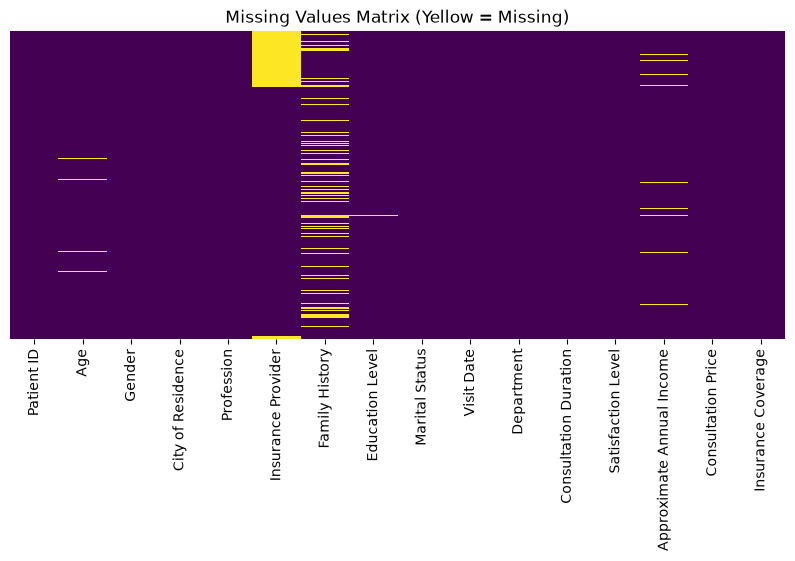

In [184]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Matrix (Yellow = Missing)')
plt.show()

The missing value heatmap above illustrates the distribution and structure of missingness across the dataset:

* **Primary Contributors to Missingness:** Missing data is overwhelmingly concentrated in two categorical features: `Insurance Provider` (1,910 missing values) and `Family History` (1,993 missing values).
* **Patient-Level Systematic Patterns:** The continuous vertical block observed in `Insurance Provider` indicates systematic missingness at the patient level, where specific patients lack insurance provider information across all recorded consultations.
* **Random Sporadic Missingness:** In contrast, `Family History` exhibits a scattered pattern across rows, representing sporadic non-reporting during individual clinical visits rather than a structural omission.
* **Low-Volume Omissions:** Demographic and financial features (`Age`, `Education Level`, `Approximate Annual Income`, and `Insurance Coverage`) display isolated, minimal gaps, confirming that missing values in these fields represent a minor fraction of the total observations.

## <font color='turquoise'>1.3.2 Handling Missing Values

In [185]:
df_imputed = df.copy()

for col in ['Age', 'Education Level']:
    df_imputed[col] = df_imputed.groupby('Patient ID')[col].ffill().bfill()

df_imputed['Insurance Provider'] = df_imputed.groupby('Patient ID')['Insurance Provider'].ffill().bfill()

rate_by_provider = {0.0: 'None', 0.8: 'Provider A', 0.9: 'Provider B', 0.7: 'Provider C', 1.0: 'Provider D'}
ratio = (df_imputed['Insurance Coverage'] / df_imputed['Consultation Price']).round(1)

df_imputed['Insurance Provider'] = df_imputed['Insurance Provider'].fillna(ratio.map(rate_by_provider))

provider_rates = {'None': 0.0, 'Provider A': 0.8, 'Provider B': 0.9, 'Provider C': 0.7, 'Provider D': 1.0}
expected_rate = df_imputed['Insurance Provider'].map(provider_rates)

df_imputed['Insurance Coverage'] = df_imputed['Insurance Coverage'].fillna(expected_rate * df_imputed['Consultation Price'])

income_median = df_imputed.groupby('Patient ID')['Approximate Annual Income'].transform('median')

df_imputed['Approximate Annual Income'] = df_imputed['Approximate Annual Income'].fillna(income_median)

df_imputed['Family History'] = df_imputed['Family History'].fillna('Unknown')

print("Missing values after imputation:")
print(df_imputed.isnull().sum())

Missing values after imputation:
Patient ID                   0
Age                          0
Gender                       0
City of Residence            0
Profession                   0
Insurance Provider           0
Family History               0
Education Level              0
Marital Status               0
Visit Date                   0
Department                   0
Consultation Duration        0
Satisfaction Level           0
Approximate Annual Income    0
Consultation Price           0
Insurance Coverage           0
dtype: int64


To handle the missing data identified across the dataset, a multi-tiered imputation strategy was implemented based on domain rules, patient-level consistency, and mathematical relationships between variables:

* **Demographic Variables (`Age` & `Education Level`):** 
  Since age and formal education level are invariant characteristics for a given individual across the short observational timeframe, missing values were propagated directly from each patient's other recorded clinical visits (`ffill().bfill()` grouped by `Patient ID`). This restores true historical values without introducing synthetic noise.

* **Insurance Provider (`Insurance Provider`):** 
  Imputation was carried out in two sequential steps:
  1. *Patient-Level Propagation:* Missing provider values were first filled using known insurance records from the same patient's other visits.
  2. *Deterministic Coverage Ratio Mapping:* For patients with no provider recorded across all visits, the provider was reverse-engineered using the exact ratio between insurance coverage and consultation price ($\text{Ratio} = \frac{\text{Insurance Coverage}}{\text{Consultation Price}}$). Since each provider operates on a fixed coverage rate ($0.0 \rightarrow \text{None}$, $0.7 \rightarrow \text{Provider C}$, $0.8 \rightarrow \text{Provider A}$, $0.9 \rightarrow \text{Provider B}$, $1.0 \rightarrow \text{Provider D}$), the underlying provider was mapped deterministically.

* **Insurance Coverage (`Insurance Coverage`):** 
  Missing values were imputed deterministically by applying the corresponding insurance provider's coverage rate to the total consultation cost ($\text{Coverage} = \text{Provider Rate} \times \text{Consultation Price}$). This preserves exact mathematical consistency across financial fields.

* **Approximate Annual Income (`Approximate Annual Income`):** 
  Because annual income exhibits minor reporting variations across visits, missing entries were imputed using the median income calculated per patient (`transform('median')`). This approach reduces distortion from single-visit anomalies while preserving zero-income entries for young or unemployed patients.

* **Family History (`Family History`):** 
  Given the sporadic nature of missing medical history entries and the categorical structure of the feature, remaining missing values were explicitly imputed as `'Unknown'`. This avoids fabricating clinical background while retaining all patient records for subsequent analytical steps.

**Imputation decisions**

| Variable | Strategy | Why |
|---|---|---|
| Age, Education Level | Fill with the patient's own value from other visits | Static per patient and always available; no information is invented. |
| Insurance Provider | Infer from `coverage / price`, fall back to the patient's other visits | Each provider pays a fixed share (A 80%, B 90%, C 70%, D 100%, None 0%), so the ratio is a fingerprint of the provider. |
| Approximate Annual Income | Leave missing per visit; use the patient **median** in the ABT (2.1.1) | Income varies a little from visit to visit; a median is robust and every patient has at least one value. |
| Insurance Coverage | Recompute `rate x price` in 1.4.9 | Deterministic business rule; needs a validated price first. |

The ratio table above shows the evidence: for every provider the minimum equals the median rate (A 0.8, B 0.9, C 0.7, D 1.0, None 0); the few larger maxima are the 6 off-rule rows treated in 1.4.9.

Group-mean imputation was rejected: it would blur genuine differences between patients.

## <font color='turquoise'>1.4 Handle Inconsistent Data

[Back to TOC](#toc)



<a id="1_4_1"></a>

## <font color='turquoise'>1.4.1 Identifying Inconsistent Data

<a id="1_4_2"></a>

## <font color='turquoise'>1.4.2 Correcting and Standardizing Inconsistent Data

<a id="1_5"></a>

## <font color='turquoise'>1.5 Identifying and Handling Outliers
[Back to TOC](#toc)

<a id="1_5_1"></a>

## <font color='turquoise'>1.5.1 Detecting Outliers in Numerical Variables

,Age,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
count,9887.0,9943.0,9943.0,9791.0,9943.0,9894.0
mean,50.7,67.8,3.2,43460.7,187.6,115.5
std,31.2,32.5,1.6,268995.9,865.7,79.4
min,0.0,15.0,1.0,0.0,50.0,0.0
25%,23.0,41.0,2.0,31161.0,111.3,59.7
50%,52.0,68.0,3.0,40897.0,159.7,116.2
75%,75.0,94.0,5.0,50717.5,199.9,165.7
max,195.0,600.0,6.0,11970900.0,39999.2,421.9



Age | rows outside the IQR limits: 36
Consultation Duration | rows outside the IQR limits: 10
Satisfaction Level | rows outside the IQR limits: 0
Approximate Annual Income | rows outside the IQR limits: 2271
Consultation Price | rows outside the IQR limits: 239
Insurance Coverage | rows outside the IQR limits: 76


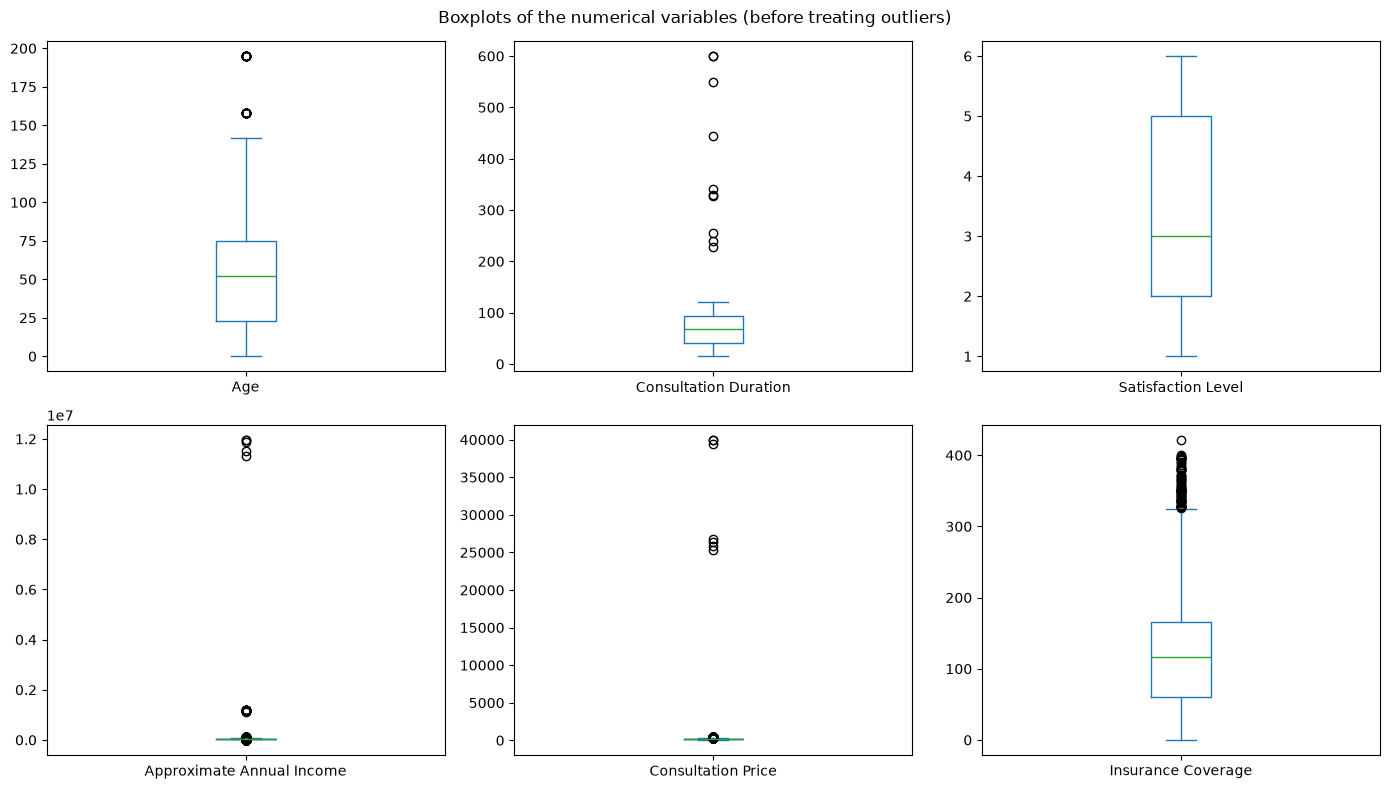

In [186]:
# Select numerical columns from the DataFrame
num_cols = ["Age", "Consultation Duration", "Satisfaction Level", "Approximate Annual Income", "Consultation Price", "Insurance Coverage"]

# min and max already show some strange values (age 195, rating 6, price 39999...)
display(df[num_cols].describe().round(1))

# IQR rule (1.5 x IQR) for each variable
print()
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(col, "| rows outside the IQR limits:", n_outliers)

df[num_cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(14, 8))
plt.suptitle("Boxplots of the numerical variables (before treating outliers)")
plt.tight_layout()
plt.show()

The describe table and the boxplots show a few values that are far away from the rest: ages up to 195, prices up to £39,999, incomes up to £12M, durations up to 600 minutes and a rating of 6.

The IQR rule alone is not good to decide what to change. It marks about 2,300 incomes and 241 prices as outliers, but most of them are normal values: many children and students have an income of 0, which makes the distribution very skewed, and the price depends on the department (see below). So we use the IQR as a first look and then check each variable with what is possible in the real world and with the variable description in the project statement.

In [187]:
num_vars = [
    "Age", 
    "Consultation Duration", 
    "Satisfaction Level", 
    "Approximate Annual Income", 
    "Consultation Price", 
    "Insurance Coverage"
]

# Create 2x6 grid: Row 1 = Boxplots, Row 2 = Histograms
fig = make_subplots(
    rows=2, cols=len(num_vars),
    subplot_titles=num_vars,
    vertical_spacing=0.12,
    horizontal_spacing=0.04
)

# Flexible color palette
palette = px.colors.qualitative.Plotly

for i, var in enumerate(num_vars):
    color = palette[i % len(palette)]
    
    # 1. Boxplot (Interactive IQR & Outlier View)
    fig.add_trace(
        go.Box(
            y=df[var].dropna(),
            name=var,
            marker_color=color,
            boxpoints='outliers',
            hovertemplate=f"<b>{var}</b><br>Value: %{{y}}<extra></extra>"
        ),
        row=1, col=i+1
    )
    
    # 2. Histogram (Distribution Density)
    fig.add_trace(
        go.Histogram(
            x=df[var].dropna(),
            name=var,
            marker_color=color,
            opacity=0.75,
            showlegend=False,
            hovertemplate=f"<b>{var}</b><br>Range: %{{x}}<br>Count: %{{y}}<extra></extra>"
        ),
        row=2, col=i+1
    )

fig.update_layout(
    title_text="<b>Visual Exploration of Numerical Outliers and Distributions</b>",
    title_font=dict(size=20, color='#009E91'),
    template="plotly_white",
    height=650,
    showlegend=False,
    margin=dict(l=40, r=40, t=80, b=40)
)

fig.show()

#### **1. Age**
* **Boxplot & IQR:** The majority of the observations are concentrated between 20 and 75 years of age (with a median around 50 years). However, there are clear extreme outliers in the upper tail, with recorded ages exceeding 150 years (reaching close to 200 years), which represent obvious data entry errors or logical inconsistencies that require treatment.
* **Histogram:** Shows a relatively continuous distribution within the plausible biological range (0 to 100 years), followed by an abrupt drop-off and isolated, sparse entries well above 100 years.

#### **2. Consultation Duration**
* **Boxplot & IQR:** The typical interquartile range lies below 100 minutes. However, a significant number of extreme outliers are identified with durations between 200 and 600 minutes (up to 10 hours per consultation), indicating potential time recording errors or non-standard clinical events.
* **Histogram:** Displays a heavy concentration in the 0 to 100-minute range, followed by a wide gap and residual low frequencies above 200 minutes.

#### **3. Satisfaction Level**
* **Boxplot & IQR:** The variable typically ranges across the ordinal scale from 1 to 5. Notably, there is a data point at the upper bound equal to 6 (or slightly above 5), configuring an out-of-bounds scale inconsistency (1–5 scale). There are no traditional outliers driven by IQR distance, but rather a value exceeding the allowed nominal range.
* **Histogram:** Exhibits an approximately uniform distribution between levels 1 and 5, along with a marginal frequency at level 6.

#### **4. Approximate Annual Income**
* **Boxplot & IQR:** The vast majority of records are compressed near zero or within standard income ranges, whereas extreme outliers appear in the 11M to 12M range (£11M to £12M), severely distorting the visual scale of the plot.
* **Histogram:** Due to the multi-million values, the histogram is entirely compressed into the first bin near zero, highlighting extreme right-skewness caused by these aberrant data points.

#### **5. Consultation Price**
* **Boxplot & IQR:** Similar to annual income, most consultation prices remain within typical ranges. However, extreme outliers ranging from £25k to £40k per consultation are present, signaling billing anomalies or severe data corruptions.
* **Histogram:** The visual representation is compressed into a single vertical bar at the origin of the x-axis due to the wide amplitude introduced by these extreme values.

#### **6. Insurance Coverage**
* **Boxplot & IQR:** Demonstrates a well-behaved distribution with a median around £110–£120 and a reasonable interquartile range. A few isolated outliers exist above the upper whisker (~£325 up to £420), representing exceptionally high coverage limits, but remaining within a plausible scale compared to the other financial features.
* **Histogram:** Displays a continuous, unimodal distribution with mild right-skewness, reflecting expected real-world behavior for insurance copayment and coverage variables.

In [ ]:
outlier_summary = []

for var in num_vars:
    series = df[var].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    
    outlier_summary.append({
        'Variable': var,
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outliers Count': len(outliers),
        '% Outliers': round((len(outliers) / len(series)) * 100, 2)
    })

df_outliers = pd.DataFrame(outlier_summary)
display(df_outliers)

,Variable,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outliers Count,% Outliers
0,Age,23.00,74.00,51.00,-53.50,150.50,0,0.00
1,Consultation Duration,41.00,94.00,53.00,-38.50,173.50,0,0.00
2,Satisfaction Level,2.00,4.00,2.00,-1.00,7.00,0,0.00
3,Approximate Annual Income,31161.00,50717.50,19556.50,1826.25,80052.25,2271,23.19
4,Consultation Price,111.35,199.93,88.58,-21.52,332.80,235,2.36
5,Insurance Coverage,59.64,165.67,106.03,-99.41,324.72,75,0.76


#### **Logical Inconsistencies & Data Entry Errors**
* **Age:** Records exceeding biological limits (>100 years, e.g., ~150–200) will be filtered out or replaced as missing values during logic-based cleaning.
* **Satisfaction Level:** Values outside the valid 1–5 range (e.g., level 6) will be capped or corrected to match the survey scale definitions.
* **Approximate Annual Income & Consultation Price:** Multi-million incomes (£11M–£12M) and consultation costs in the tens of thousands (£25k–£40k) severely distort distributions and represent data collection artifacts rather than legitimate domain extremes. These corrupt values will be remediated.

#### **Domain-Plausible Extreme Values**
* **Insurance Coverage & Consultation Duration:** Values beyond the upper whiskers ($1.5 \times \text{IQR}$) that fall within plausible operational ranges (e.g., complex procedures or premium coverage tiers) will be retained to preserve genuine patient profile variability for downstream feature engineering and clustering.

<a id="1_5_2"></a>

## <font color='turquoise'> 1.5.2 Deciding How to Handle Outliers

| Variable | Outlier | Decision | Why |
|---|---|---|---|
| Age | 103 rows (5 patients) above 110 | Correct: subtract 100 | Typing error with an extra "1", confirmed by patient 1198 and by the profession and education |
| Consultation Price | 7 rows above £1000 | Correct: divide by 100 | The result is inside the normal range of the department |
| Approximate Annual Income | 21 rows above £1M | Correct: divide by 10 (£1M-£10M) or by 100 (above £10M) | The result is close to the highest normal incomes and to the patient's other visits |
| Income = 0 | 110 patients | Keep | Valid value (mostly children and students) |
| Consultation Duration | 10 rows above 120 min | Impute with the median of the department | The extreme values are not a clear multiple of a normal duration, so the real value is unknown |
| Satisfaction Level | 719 rows with a 6 | Set to missing | The rating is impossible and the real opinion is unknown. We do not change it to 5 because it would invent good ratings |
| Insurance Coverage | 6 rows higher than the price | Recompute: provider rate x price | All the other rows follow this rule exactly |

We do not remove any row or patient: the errors have a clear pattern or can be replaced, and removing visits would lose real information (and patients).

POR FAZER- RAFAEL


After the corrections all the values are inside the possible ranges and we still have the 10,008 visits of the 500 patients. The boxplots now show compact distributions without the extreme points.

Note for the ABT: the 719 ratings that became missing are ignored by `mean()` and `min()`. The share of low ratings should be calculated only with the valid ratings (for example with `dropna()` first).

### ATÉ AQUI RAFAEL

<a id="2"></a>

## <font color='turquoise'> 2. Part B - Feature Engineering & ABT Construction

[Back to TOC](#toc)


<a id="2_1"></a>

## <font color='turquoise'> 2.1 Patient-Level ABT Construction

<a id="2_1_1"></a>

## <font color='turquoise'> 2.1.1 Static Attributes

<a id="2_1_2"></a>

## <font color='turquoise'> 2.1.2 Visit Behaviour Features

<a id="2_1_3"></a>

## <font color='turquoise'> 2.1.3 Financial Features

<a id="2_1_4"></a>
## <font color='turquoise'> 2.1.4 Satisfaction Features

<a id="2_1_5"></a>

## <font color='turquoise'> 2.1.5 Recency and Activity Features

<a id="2_2"></a>

## <font color='turquoise'> 2.2 Data Dictionary

[Back to TOC](#toc)

<a id="2_3"></a>

## <font color='turquoise'>  2.3 Exporting the ABT

[Back to TOC](#toc)

<a id="3"></a>

## <font color='turquoise'>  3. Part C - Exploratory Visualization & Insights

[Back to TOC](#toc)


<a id="3_1"></a>

## <font color='turquoise'> 3.1 Patient Demographics

[Back to TOC](#toc)

<a id="3_1_1"></a>

## <font color='turquoise'> 3.1.1 Age Distribution

<a id="3_1_2"></a>

## <font color='turquoise'>  3.1.2 Gender Distribution

<a id="3_1_3"></a>

## <font color='turquoise'> 3.1.3 Income Distribution

<a id="3_2"></a>

## <font color='turquoise'> 3.2 Department and Service Usage

[Back to TOC](#toc)

<a id="3_2_1"></a>

## <font color='turquoise'> 3.2.1 Consultations by Department

<a id="3_2_2"></a>

## <font color='turquoise'> 3.2.2 Consultations Over Time

<a id="3_2_3"></a>
## <font color='turquoise'>  3.2.3 Department Usage by Gender or Age Group

<a id="3_3"></a>

## <font color='turquoise'> 3.3 Patient Satisfaction

[Back to TOC](#toc)

<a id="3_3_1"></a>

## <font color='turquoise'> 3.3.1 Satisfaction by Department

<a id="3_3_2"></a>

## <font color='turquoise'> 3.3.2 Satisfaction by Patient Segment

<a id="3_4"></a>

## <font color='turquoise'> 3.4 Additional Visualizations

[Back to TOC](#toc)


<a id="3_5"></a>
## <font color='turquoise'>  3.5 Management Questions and Key Insights

[Back to TOC](#toc)